In [1]:
from sklearn.metrics import silhouette_score
import numpy as np
import scanpy as sc

In [2]:
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/celltype_check/multi_raw.h5ad')
scdata

AnnData object with n_obs × n_vars = 21861 × 9911
    obs: 'species', 'tissues', 'samples', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'cluster', 'celltype', 'coarse_celltype', 'eco', 'leiden_R', 'new_leiden', 'new_anno', 'split_label', 'sly_anno'
    var: 'gene_ids', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'celltype_colors', 'dendrogram_new_anno', 'eco_colors', 'hvg', 'leiden', 'leiden_R', 'leiden_R_colors', 'leiden_colors', 'neighbors', 'new_anno_colors', 'new_leiden_colors', 'pca', 'rank_genes_groups', 'species_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'connectivities', 'distances'

In [ ]:
import numpy as np
from tqdm import tqdm 

def get_connectivity_matrix_fast(scdata):
    labels = scdata.obs.leiden.values.astype(object)
    return (labels[:, None] == labels[None, :]).astype(int)

res_dic = {}

for alpha in [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]:
    print(alpha)
    for seed in tqdm(range(100)):
        sc.tl.leiden(scdata, resolution=alpha, random_state=seed)
        if seed == 0:
            C = get_connectivity_matrix_fast(scdata)
        else:
            C += get_connectivity_matrix_fast(scdata)
    res_dic[alpha] = C / 100


In [6]:
import numpy as np
from tqdm import tqdm
from multiprocessing import Pool, cpu_count
import scanpy as sc
import copy

# 假设你已经定义好了 scdata，这里是拷贝一份用于进程间操作
scdata_global = None  # 全局变量用于存储数据

def init_worker(scdata_copy):
    global scdata_global
    scdata_global = copy.deepcopy(scdata_copy)

def process_seed(seed_alpha):
    seed, alpha = seed_alpha  # 拆包参数
    global scdata_global
    
    # 复制一份数据，避免进程之间干扰
    adata = copy.deepcopy(scdata_global)
    
    # 运行 Leiden 聚类
    sc.tl.leiden(adata, resolution=alpha, random_state=seed)
    
    # 获取连接矩阵
    labels = adata.obs.leiden.values.astype(object)
    connect_matrix = (labels[:, None] == labels[None, :]).astype(np.int8)
    
    return connect_matrix

def parallel_run(alpha, n_seeds=100, n_jobs=-1):
    if n_jobs == -1:
        n_jobs = 100
        
    params = [(seed, alpha) for seed in range(n_seeds)]
    
    with Pool(n_jobs, initializer=init_worker, initargs=(scdata_global,)) as pool:
        results = list(tqdm(pool.imap(process_seed, params), total=n_seeds))
    
    # 累加所有结果
    consensus = np.sum(results, axis=0).astype(np.float32)
    consensus /= n_seeds
    return consensus

In [ ]:
res_dic = {}

# 注意：这里要确保 scdata_global 被正确初始化
scdata_global = scdata  # 或者 deep copy 一次

for alpha in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]:
    print(f"Processing resolution: {alpha}")
    res_dic[alpha] = parallel_run(alpha, n_seeds=100)

In [ ]:
tmp = []
delta = 0.25
for key in res_dic:
    x = res_dic[key].flatten()
    idx_1 = x >= 0.5 - delta
    idx_2 = x <= 0.5 + delta
    idx = np.logical_and(idx_1, idx_2)
    print(f'{key}: {np.sum(idx)/len(idx)}')
    tmp.append(np.log(np.sum(idx)/len(idx)))
plt.plot(tmp)
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# 数据
y_values = tmp
x_labels = [str(0.1*i)[:3] for i in range(1, 11)]

# 创建 x 坐标（整数位置）
x_positions = range(len(y_values))

# 绘图
plt.figure(figsize=(10, 6))
plt.plot(x_positions, y_values, marker='o', linestyle='-', color='b')

# 设置 x 轴标签
plt.xticks(x_positions, x_labels)

# 添加标题和坐标轴标签
#plt.title('')
plt.xlabel('resolution')
plt.ylabel('unstability (lower is better)')


# 显示图形
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score 


s_list = []
for resolution in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]:
    sc.tl.leiden(scdata, resolution=resolution)
    s_list.append(silhouette_score(scdata.obsm['X_pca_harmony'], scdata.obs.leiden.values.astype(object)))

In [ ]:
plt.plot(s_list)
plt.show()

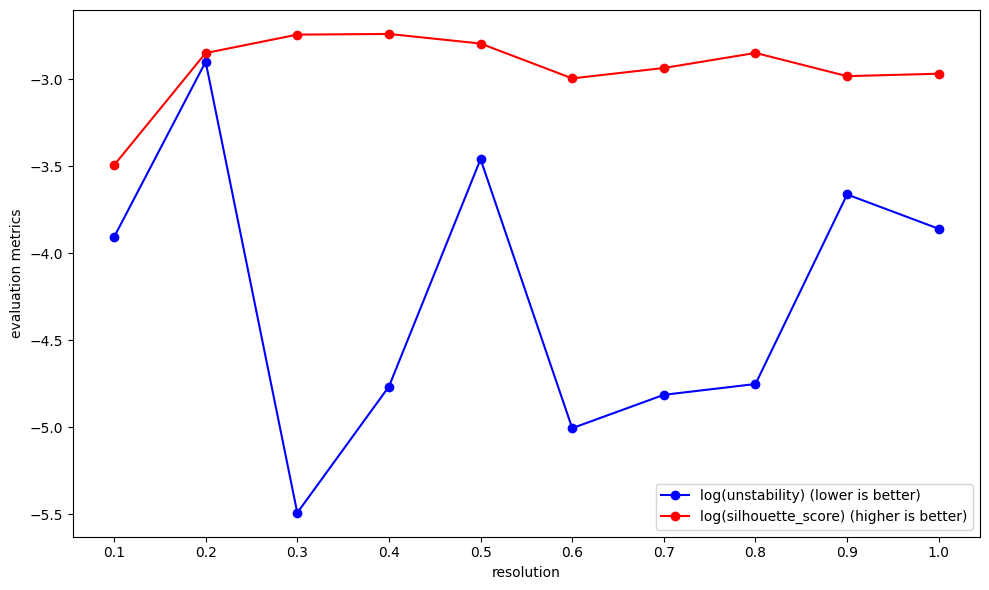

In [ ]:
import matplotlib.pyplot as plt

# 数据
y_values = tmp
x_labels = [str(0.1*i)[:3] for i in range(1, 11)]

# 创建 x 坐标（整数位置）
x_positions = range(len(y_values))


# 绘图
plt.figure(figsize=(10, 6))
plt.plot(x_positions, y_values, marker='o', linestyle='-', color='b',label = 'log(unstability) (lower is better)')
plt.plot(x_positions, np.log(np.array(s_list)), marker='o', linestyle='-', color='r', label = 'log(silhouette_score) (higher is better)')


# 设置 x 轴标签
plt.xticks(x_positions, x_labels)

# 添加标题和坐标轴标签
#plt.title('')
plt.xlabel('resolution')
plt.ylabel('evaluation metrics')
plt.legend()

# 显示图形
plt.tight_layout()
plt.savefig('requirement_3.pdf')
plt.show()